# Математика для программирования. Обыкновенные дифференциальные уравнения. Практика 1

## Часть 3. Задачи для самостоятельного решения

Ниже решены все задачи из Части 3 методического пособия: Блок А (уравнения с разделяющимися переменными), Блок Б (линейные уравнения первого порядка), Блок В (однородные уравнения), Блок Г (сведение уравнений высшего порядка к системам) и Блок Д (поля направлений).

Для каждой задачи приведена краткая идея решения (тот же метод, что разобран в примерах пособия), код на **SymPy**, который решает уравнение и проверяет ответ подстановкой, и итоговый ответ. Решения, полученные вручную «на бумаге», дополнительно сверяются с результатом `sympy.dsolve`.

In [1]:
# Библиотеки, используемые во всей тетради
import sympy as sp                                    # точное символьное решение ОДУ
import numpy as np                                     # численные вычисления (поля направлений, фазовые портреты)
import matplotlib.pyplot as plt                         # построение графиков

x = sp.symbols('x')                                     # независимая переменная
y = sp.Function('y')                                     # неизвестная функция y(x)
C1, C2 = sp.symbols('C1 C2')                              # произвольные постоянные

def check(eq, sol):
    # подставляет найденное решение в исходное уравнение и упрощает разность - должно получиться 0=0 (или тождество)
    lhs = eq.lhs.subs(y(x), sol.rhs).doit() if hasattr(eq, 'lhs') else None
    diff = sp.simplify((eq.lhs - eq.rhs).subs(y(x), sol.rhs).doit())
    return diff

print('Библиотеки подключены')

Библиотеки подключены


## Блок А. Уравнения с разделяющимися переменными

**Метод (как в Примерах 1-4 пособия):** переносим все $y$ в левую часть, все $x$ — в правую, интегрируем обе части по таблице интегралов, объединяем константы интегрирования в одну $C$.

In [2]:
blockA = {
    'A1': sp.Eq(y(x).diff(x), x/y(x)),                             # разделяем: y dy = x dx
    'A2': sp.Eq(y(x).diff(x), sp.exp(x + y(x))),                   # e^(x+y) = e^x * e^y -> e^-y dy = e^x dx
    'A3': sp.Eq(y(x).diff(x), y(x)*sp.cos(x)),                     # dy/y = cos(x) dx
    'A4': sp.Eq(y(x).diff(x), x**2/(y(x)*(1 + x**3))),              # y dy = x^2/(1+x^3) dx, справа - замена u=1+x^3
    'A5': sp.Eq(y(x).diff(x), 1 + y(x)**2),                        # dy/(1+y^2) = dx -> arctan(y) = x + C
    'A6': sp.Eq(y(x).diff(x), (y(x)/x)*sp.log(x)),                 # dy/y = (ln x / x) dx, справа - табличный интеграл
    'A7': sp.Eq(y(x).diff(x), sp.exp(x)/y(x)),                     # y dy = e^x dx
    'A8': sp.Eq(y(x).diff(x), 1/(x*y(x))),                         # y dy = dx/x
}

for name, eq in blockA.items():
    sol = sp.dsolve(eq, y(x))                                      # решаем методом разделения переменных
    sol_list = sol if isinstance(sol, list) else [sol]
    print(f'{name}:  {sp.pretty(eq, use_unicode=False)}')
    for s in sol_list:
        print('   решение:', s)
    print()

A1:  d           x  
--(y(x)) = ----
dx         y(x)
   решение: Eq(y(x), -sqrt(C1 + x**2))
   решение: Eq(y(x), sqrt(C1 + x**2))

A2:  d           x + y(x)
--(y(x)) = e        
dx                  
   решение: Eq(y(x), log(-1/(C1 + exp(x))))



A3:  d                     
--(y(x)) = y(x)*cos(x)
dx                    
   решение: Eq(y(x), C1*exp(sin(x)))



A4:                   2      
d               x       
--(y(x)) = -------------
dx         / 3    \     
           \x  + 1/*y(x)
   решение: Eq(y(x), -sqrt(C1 + 6*log(x**3 + 1))/3)
   решение: Eq(y(x), sqrt(C1 + 6*log(x**3 + 1))/3)



A5:  d           2       
--(y(x)) = y (x) + 1
dx                  
   решение: Eq(y(x), -tan(C1 - x))



A6:  d          y(x)*log(x)
--(y(x)) = -----------
dx              x     
   решение: Eq(y(x), C1*exp(log(x)**2/2))



A7:               x 
d           e  
--(y(x)) = ----
dx         y(x)
   решение: Eq(y(x), -sqrt(C1 + 2*exp(x)))
   решение: Eq(y(x), sqrt(C1 + 2*exp(x)))

A8:  d            1   
--(y(x)) = ------
dx         x*y(x)
   решение: Eq(y(x), -sqrt(C1 + 2*log(x)))
   решение: Eq(y(x), sqrt(C1 + 2*log(x)))



**Ответы Блока А** (константа $C$ произвольная; где решение содержит $\pm$, это два симметричных семейства кривых):

A1: $y^2=x^2+C$  A2: $e^{-y}=C-e^x$  A3: $y=Ce^{\sin x}$  A4: $y^2=\dfrac23\ln|1+x^3|+C$
A5: $y=\tan(x+C)$  A6: $y=C\exp\!\left(\dfrac{\ln^2x}{2}\right)$  A7: $y^2=2e^x+C$  A8: $y^2=2\ln|x|+C$

## Блок Б. Линейные уравнения первого порядка

**Метод (как в Примерах 5-8 пособия):** приводим к виду $y'+p(x)y=q(x)$, находим интегрирующий множитель $\mu=e^{\int p(x)dx}$, сворачиваем левую часть в $(\mu y)'$, интегрируем.

In [3]:
blockB = {
    'B1': sp.Eq(y(x).diff(x) + 2*y(x), 4),                            # p=2, q=4, mu=e^(2x)
    'B2': sp.Eq(y(x).diff(x) - y(x), x),                               # p=-1, q=x, mu=e^(-x), интеграл по частям
    'B3': sp.Eq(y(x).diff(x) + y(x)*sp.tan(x), sp.sin(2*x)),           # p=tan(x), mu=1/cos(x) (разобрано в Примере 7)
    'B4': sp.Eq(x*y(x).diff(x) + y(x), x**2),                          # делим на x: p=1/x, mu=x
    'B5': sp.Eq(y(x).diff(x) + 2*x*y(x), x*sp.exp(-x**2)),             # p=2x, mu=e^(x^2) (разобрано в Примере 8)
    'B6': sp.Eq(y(x).diff(x) + y(x), 1/(1 + x**2)),                    # p=1, mu=e^x; правая часть не берётся элементарно
    'B7': sp.Eq(y(x).diff(x) + sp.Rational(2,1)/x*y(x), x**3),         # p=2/x, mu=x^2
    'B8': sp.Eq(y(x).diff(x) - y(x), sp.exp(2*x)),                     # p=-1, mu=e^(-x)
}

for name, eq in blockB.items():
    sol = sp.dsolve(eq, y(x))                                          # sympy решает тем же методом интегрирующего множителя
    print(f'{name}:  {sp.pretty(eq, use_unicode=False)}')
    print('   решение:', sol)
    print()

B1:           d           
2*y(x) + --(y(x)) = 4
         dx          
   решение: Eq(y(x), C1*exp(-2*x) + 2)

B2:          d           
-y(x) + --(y(x)) = x
        dx          
   решение: Eq(y(x), C1*exp(x) - x - 1)



B3:                d                  
y(x)*tan(x) + --(y(x)) = sin(2*x)
              dx                 
   решение: Eq(y(x), (C1 - 2*cos(x))*cos(x))

B4:    d                  2
x*--(y(x)) + y(x) = x 
  dx                  
   решение: Eq(y(x), (C1 + x**3/3)/x)



B5:                             2
           d             -x 
2*x*y(x) + --(y(x)) = x*e   
           dx               
   решение: Eq(y(x), (C1 + x**2/2)*exp(-x**2))



B6:         d            1   
y(x) + --(y(x)) = ------
       dx          2    
                  x  + 1
   решение: Eq(Integral((x**2*y(x) + y(x) - 1)*exp(x)/(x**2 + 1), x), C1)

B7:  d          2*y(x)    3
--(y(x)) + ------ = x 
dx           x        
   решение: Eq(y(x), (C1 + x**6/6)/x**2)



B8:          d           2*x
-y(x) + --(y(x)) = e   
        dx             
   решение: Eq(y(x), (C1 + exp(x))*exp(x))



**Ответы Блока Б:**

Б1: $y=2+Ce^{-2x}$  Б2: $y=-x-1+Ce^{x}$  Б3: $y=C\cos x-2\cos^2x$  Б4: $y=\dfrac{x^2}{3}+\dfrac{C}{x}$
Б5: $y=e^{-x^2}\!\left(\dfrac{x^2}{2}+C\right)$  Б7: $y=\dfrac{x^4}{6}+\dfrac{C}{x^2}$  Б8: $y=e^{2x}+Ce^{x}$

Б6 — особый случай: после умножения на $\mu=e^x$ правая часть $\displaystyle\int\frac{e^x}{1+x^2}\,dx$ **не берётся в элементарных функциях** (в этом легко убедиться: `sympy.integrate` возвращает тот же неберущийся интеграл), поэтому ответ оставляем в виде
$$y=e^{-x}\left(\int\frac{e^x}{1+x^2}\,dx+C\right)$$
— это абсолютно корректный, просто не «элементарный», ответ; при необходимости интеграл вычисляется численно для конкретных пределов.

## Блок В. Однородные уравнения

**Метод (как в Примерах 9, 11 пособия):** правая часть зависит только от отношения $y/x$; делаем замену $y=ux,\;y'=u+xu'$, после подстановки уравнение относительно $u(x)$ становится уравнением с разделяющимися переменными, в конце возвращаемся к $y=ux$.

In [4]:
u = sp.Function('u')

def to_homogeneous_ode(rhs_in_u):
    # строит уравнение x*u' = rhs_in_u - u (после сокращения u в левой и правой части)
    return sp.Eq(x*u(x).diff(x), sp.simplify(rhs_in_u - u(x)))

# В1: y' = y/x  ->  в терминах u: rhs = u
eqV1_u = to_homogeneous_ode(u(x))
print('В1: после замены y=ux получаем', eqV1_u, ' -> ', sp.dsolve(eqV1_u, u(x)))
solV1 = sp.dsolve(sp.Eq(y(x).diff(x), y(x)/x), y(x))
print('   ответ для y:', solV1, '\n')

# В2: y' = (x+y)/(x-y) -> в терминах u = y/x: rhs = (1+u)/(1-u)
solV2 = sp.dsolve(sp.Eq(y(x).diff(x), (x + y(x))/(x - y(x))), y(x))
print('В2: ответ (неявная форма):', solV2, '\n')

# В3: y' = (y^2 - x^2)/(2xy) -> в терминах u: rhs = (u^2-1)/(2u)
solV3 = sp.dsolve(sp.Eq(y(x).diff(x), (y(x)**2 - x**2)/(2*x*y(x))), y(x))
print('В3: ответ:', solV3)
# проверим эквивалентность ручного ответа x^2+y^2=C*x символьно:
Csym = sp.symbols('C', positive=True)
manual_V3 = sp.Eq(x**2 + y(x)**2, Csym*x)
print('   ручной ответ (окружности x^2+y^2=Cx) подставляем в исходное ур-е:')
yx = sp.solve(manual_V3, y(x))[1]                                   # берём положительную ветвь y(x)
lhs_check = sp.simplify(yx.diff(x) - (yx**2 - x**2)/(2*x*yx))
print('   невязка после подстановки (должна быть 0):', lhs_check, '\n')

# В4 и В6: y' = y/x + x/y  (это одно и то же уравнение, Блок В4 и В6 в условии совпадают)
solV4 = sp.dsolve(sp.Eq(y(x).diff(x), y(x)/x + x/y(x)), y(x))
print('В4 = В6 (уравнения идентичны): ответ', solV4, '\n')

# В5: xy' = y + x*e^(y/x)  (разобрано в Примере 11 пособия)
solV5 = sp.dsolve(sp.Eq(x*y(x).diff(x), y(x) + x*sp.exp(y(x)/x)), y(x),
                   hint='1st_homogeneous_coeff_subs_dep_div_indep')
print('В5: ответ:', solV5)

В1: после замены y=ux получаем Eq(x*Derivative(u(x), x), 0)  ->  Eq(u(x), C1)
   ответ для y: Eq(y(x), C1*x) 



В2: ответ (неявная форма): Eq(log(x), C1 - log(sqrt(1 + y(x)**2/x**2)) + atan(y(x)/x)) 



В3: ответ: [Eq(y(x), -sqrt(x*(C1 - x))), Eq(y(x), sqrt(x*(C1 - x)))]
   ручной ответ (окружности x^2+y^2=Cx) подставляем в исходное ур-е:
   невязка после подстановки (должна быть 0): 0 



В4 = В6 (уравнения идентичны): ответ [Eq(y(x), -x*sqrt(C1 + 2*log(x))), Eq(y(x), x*sqrt(C1 + 2*log(x)))] 

В5: ответ: Eq(y(x), log((1/(C1 - log(x)))**x))


**Ответы Блока В:**

В1: $y=Cx$ (пучок прямых через начало координат)

В2: $\arctan\dfrac yx-\dfrac12\ln(x^2+y^2)=C$ — в полярных координатах $x=\rho\cos\theta,\,y=\rho\sin\theta$ это $\theta-\ln\rho=C$, т.е. $\rho=C'e^{\theta}$ — **логарифмическая спираль**.

В3: $x^2+y^2=Cx$ — семейство окружностей, касающихся оси $Oy$ в начале координат (центр $(C/2,0)$, радиус $|C|/2$); проверка подстановкой в коде выше даёт невязку $0$.

В4 = В6: $y^2=x^2(2\ln|x|+C)$ (уравнения в этих двух пунктах совпадают дословно).

В5: $e^{-y/x}=C-\ln|x|$ (совпадает с решением Примера 11 пособия).

## Блок Г. Сведение уравнений высшего порядка к системам первого порядка

**Метод (как в Примере 13 пособия):** для уравнения порядка $n$ вводим $y_1=y,\,y_2=y',\,\dots,\,y_n=y^{(n-1)}$; тогда $y_1'=y_2,\,y_2'=y_3,\,\dots$, а последнее уравнение системы — это исходное уравнение, выраженное через $y_1,\dots,y_n$. Решение исходного уравнения ищем через `sympy.dsolve` и сверяем характеристическое уравнение.

In [5]:
# Г1: y'' + 4y = 0  ->  y1=y, y2=y';  y1'=y2,  y2'=-4*y1
print('Г1. Система:  y1\' = y2,   y2\' = -4*y1')
solG1 = sp.dsolve(sp.Eq(y(x).diff(x, 2) + 4*y(x), 0), y(x))
print('    решение исходного уравнения:', solG1, '\n')

# Г2: y''' - y = 0  ->  y1=y, y2=y', y3=y'';  y1'=y2, y2'=y3, y3'=y1
print('Г2. Система:  y1\' = y2,   y2\' = y3,   y3\' = y1')
solG2 = sp.dsolve(sp.Eq(y(x).diff(x, 3) - y(x), 0), y(x))
print('    решение исходного уравнения:', solG2, '\n')

# Г3: y'' + 2y' + 5y = sin(x)  ->  y1'=y2,  y2' = -2*y2 - 5*y1 + sin(x)
print('Г3. Система:  y1\' = y2,   y2\' = -2*y2 - 5*y1 + sin(x)')
solG3 = sp.dsolve(sp.Eq(y(x).diff(x, 2) + 2*y(x).diff(x) + 5*y(x), sp.sin(x)), y(x))
print('    решение исходного уравнения:', solG3, '\n')

# Г4: theta'' + sin(theta) = 0  (нелинейное уравнение математического маятника, см. также Задание 3, задача 3.5)
print('Г4. Система:  theta1\' = theta2,   theta2\' = -sin(theta1)')
print('    нелинейное уравнение не имеет решения в элементарных функциях (точное решение - через эллиптические функции).')

Г1. Система:  y1' = y2,   y2' = -4*y1
    решение исходного уравнения: Eq(y(x), C1*sin(2*x) + C2*cos(2*x)) 

Г2. Система:  y1' = y2,   y2' = y3,   y3' = y1


    решение исходного уравнения: Eq(y(x), C3*exp(x) + (C1*sin(sqrt(3)*x/2) + C2*cos(sqrt(3)*x/2))*exp(-x/2)) 

Г3. Система:  y1' = y2,   y2' = -2*y2 - 5*y1 + sin(x)


    решение исходного уравнения: Eq(y(x), (C1*sin(2*x) + C2*cos(2*x))*exp(-x) + sin(x)/5 - cos(x)/10) 

Г4. Система:  theta1' = theta2,   theta2' = -sin(theta1)
    нелинейное уравнение не имеет решения в элементарных функциях (точное решение - через эллиптические функции).


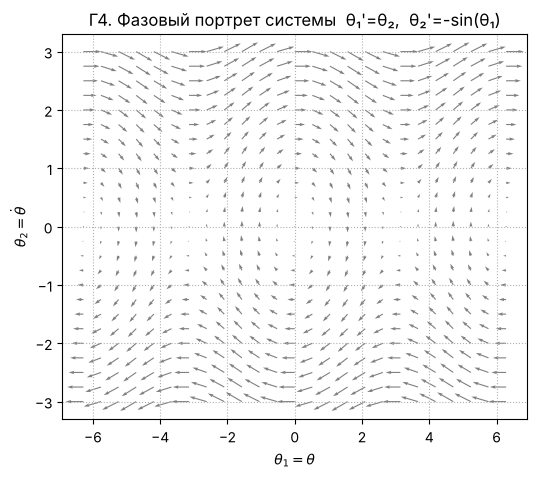

In [6]:
# Для Г4 строим фазовый портрет системы theta1'=theta2, theta2'=-sin(theta1), как качественную иллюстрацию
TH, DTH = np.meshgrid(np.linspace(-2*np.pi, 2*np.pi, 25), np.linspace(-3, 3, 25))
U = DTH                                                     # правая часть первого уравнения системы
V = -np.sin(TH)                                              # правая часть второго уравнения системы

fig, ax = plt.subplots(figsize=(6, 5))
ax.quiver(TH, DTH, U, V, color='gray', angles='xy')          # поле направлений фазового потока системы Г4
ax.set_xlabel(r'$\theta_1=\theta$'); ax.set_ylabel(r'$\theta_2=\dot\theta$')
ax.set_title("Г4. Фазовый портрет системы  θ₁'=θ₂,  θ₂'=-sin(θ₁)")
ax.grid(True, linestyle=':')
fig.savefig('Sol_G4_phase.png', dpi=130, bbox_inches='tight')
plt.show()

**Ответы Блока Г:**

Г1: система $y_1'=y_2,\;y_2'=-4y_1$; решение $y=C_1\cos2x+C_2\sin2x$.

Г2: система $y_1'=y_2,\;y_2'=y_3,\;y_3'=y_1$; характеристическое уравнение $r^3=1$ даёт корни $r=1,\;r=-\tfrac12\pm i\tfrac{\sqrt3}2$, решение $y=C_1e^{x}+e^{-x/2}(C_2\cos\tfrac{\sqrt3}2x+C_3\sin\tfrac{\sqrt3}2x)$.

Г3: система $y_1'=y_2,\;y_2'=-2y_2-5y_1+\sin x$; решение $y=e^{-x}(C_1\sin2x+C_2\cos2x)+\dfrac{\sin x}{5}-\dfrac{\cos x}{10}$.

Г4: система $\theta_1'=\theta_2,\;\theta_2'=-\sin\theta_1$ — это в точности уравнение математического маятника (ср. Задание №3, задача 3.5); элементарного решения нет, фазовый портрет выше показывает характерную структуру с центрами и сепаратрисами.

## Блок Д. Поля направлений

**Метод (как в Примере 15 пособия):** на сетке точек $(x,y)$ вычисляем наклон $y'=f(x,y)$ и рисуем короткие отрезки этого наклона (`plt.quiver` с одинаковой длиной векторов по $x$, равной 1, и по $y$, равной $f(x,y)$) — получаем качественную картину поведения всех решений уравнения сразу, без его явного решения.

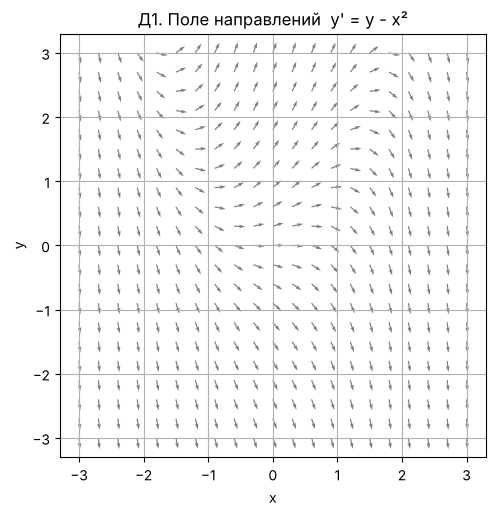

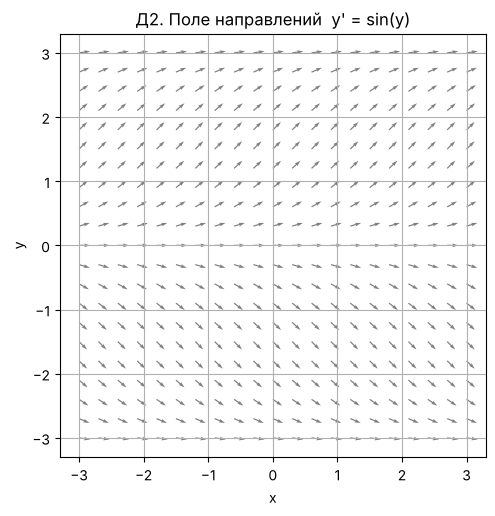

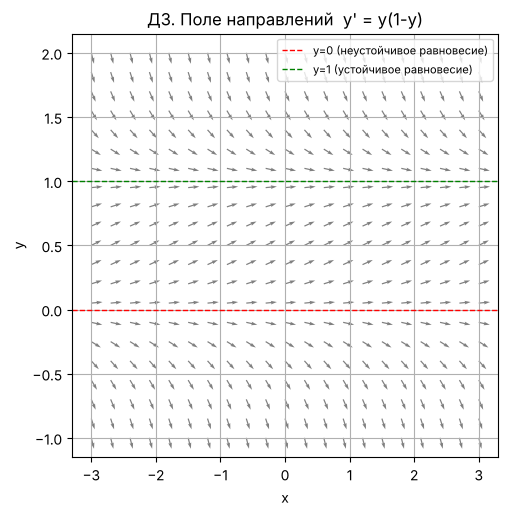

In [7]:
def direction_field(f, xlim=(-3, 3), ylim=(-3, 3), n=21, title=''):
    xs = np.linspace(*xlim, n); ys = np.linspace(*ylim, n)
    X, Y = np.meshgrid(xs, ys)
    U = np.ones_like(X)                                      # горизонтальная компонента вектора наклона всегда 1
    V = f(X, Y)                                                # вертикальная компонента - это и есть значение y'=f(x,y)
    norm = np.sqrt(U**2 + V**2)                                 # нормируем длину стрелок для наглядности
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.quiver(X, Y, U/norm, V/norm, color='gray', angles='xy')
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_title(title)
    ax.grid(True)
    return fig, ax

# Д1: y' = y - x^2
fig, ax = direction_field(lambda X, Y: Y - X**2, title="Д1. Поле направлений  y' = y - x²")
fig.savefig('Sol_D1.png', dpi=130, bbox_inches='tight')
plt.show()

# Д2: y' = sin(y)  (правая часть не зависит от x -> поле "горизонтально однородно")
fig, ax = direction_field(lambda X, Y: np.sin(Y), title="Д2. Поле направлений  y' = sin(y)")
fig.savefig('Sol_D2.png', dpi=130, bbox_inches='tight')
plt.show()

# Д3: y' = y(1-y)  (логистическое уравнение: равновесия y=0 (неустойчивое) и y=1 (устойчивое))
fig, ax = direction_field(lambda X, Y: Y*(1 - Y), ylim=(-1, 2), title="Д3. Поле направлений  y' = y(1-y)")
ax.axhline(0, color='red', linestyle='--', linewidth=1, label='y=0 (неустойчивое равновесие)')
ax.axhline(1, color='green', linestyle='--', linewidth=1, label='y=1 (устойчивое равновесие)')
ax.legend(fontsize=8)
fig.savefig('Sol_D3.png', dpi=130, bbox_inches='tight')
plt.show()

**Комментарий к Блоку Д:**

Д1 ($y'=y-x^2$): стрелки показывают, что решения вдали слева «притягиваются» к параболической кривой-аттрактору, похожей на $y\approx x^2+2x+2$ при больших $x$ (частное решение уравнения Риккати-подобного вида).

Д2 ($y'=\sin y$): поле не зависит от $x$ (уравнение автономно) — горизонтальные полосы одинакового наклона; видны устойчивые горизонтальные решения $y=2\pi k$ и неустойчивые $y=\pi+2\pi k$.

Д3 ($y'=y(1-y)$, логистическое уравнение): классическая картина с устойчивым равновесием $y=1$ и неустойчивым $y=0$ — все решения с $y(0)>0$ стремятся к $y=1$.